# Lab Exercise 08: Implement a Variational Autoencoder (VAE) for Image Reconstruction

## Aim
To implement a Variational Autoencoder (VAE) using TensorFlow/Keras to learn the latent representation of handwritten digit images from the MNIST dataset and reconstruct them.

### Real-Time Applications
- **Image Compression:** Efficient lossy compression by storing low-dimensional latent vectors instead of high-dimensional raw pixels.
- **Generative Modeling & Image Synthesis:** Sampling new, synthetic images directly from the continuous latent probability distribution.
- **Noise Reduction (Denoising):** Removing artifacts and corruptions by projecting noisy inputs into a clean latent manifold.
- **Anomaly & Outlier Detection:** Detecting irregular or out-of-distribution inputs based on high reconstruction error.

## Theoretical Background

### 1. Traditional Autoencoders vs. Variational Autoencoders (VAEs)
A standard Autoencoder maps each input image $x$ to a single deterministic point $z$ in latent space. Because there is no constraint on the distribution of these latent points, standard autoencoders suffer from "gaps" or discontinuities in latent space, making random sampling or smooth interpolation impossible.

A **Variational Autoencoder (VAE)** is a probabilistic generative model. Instead of mapping an input to a static vector, the encoder outputs parameters of a probability distribution: a mean vector $\mu$ and a log-variance vector $\log(\sigma^2)$. The latent representation $z$ is then sampled from this distribution $q_\phi(z|x) = \mathcal{N}(\mu, \sigma^2 I)$.

### 2. The Reparameterization Trick
Direct stochastic sampling $z \sim \mathcal{N}(\mu, \sigma^2)$ is non-differentiable, preventing standard backpropagation. The **Reparameterization Trick** circumvents this bottleneck by expressing the stochasticity through an auxiliary independent noise variable $\epsilon \sim \mathcal{N}(0, I)$:
$$z = \mu + \sigma \odot \epsilon = \mu + \exp\left(0.5 \times \log(\sigma^2)\right) \odot \epsilon$$
This isolates the random sampling to $\epsilon$, allowing gradients to flow freely through $\mu$ and $\log(\sigma^2)$.

### 3. The VAE Loss Function
The VAE loss is derived from the Evidence Lower Bound (ELBO) and consists of two competing objectives:
$$\mathcal{L}_{VAE} = \mathcal{L}_{reconstruction} + \mathcal{D}_{KL}(q_\phi(z|x) \parallel p(z))$$
1. **Reconstruction Loss:** Measures pixel-level fidelity using Binary Crossentropy between input $x$ and output $\hat{x}$ across all 784 pixels:
   $$\mathcal{L}_{reconstruction} = - \sum_{i=1}^{784} \left[ x_i \log \hat{x}_i + (1 - x_i) \log(1 - \hat{x}_i) \right]$$
2. **Kullback-Leibler (KL) Divergence:** Acts as a regularizer, penalizing the encoder distribution $q_\phi(z|x)$ for deviating from a standard normal prior $p(z) = \mathcal{N}(0, I)$:
   $$\mathcal{D}_{KL} = -\frac{1}{2} \sum_{j=1}^{d} \left( 1 + \log(\sigma_j^2) - \mu_j^2 - \sigma_j^2 \right)$$
This ensures the latent space remains smooth, complete, and centered around the origin.

### Step 1: Import Libraries
We import TensorFlow, NumPy, Matplotlib, and essential Keras model and layer components (`Input`, `Dense`, `Lambda`, `Model`).

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import warnings
warnings.filterwarnings('ignore')

# Step 1: Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.layers import (
    Input, Dense, Lambda
)
from tensorflow.keras.models import Model

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print("Libraries successfully imported.")

TensorFlow Version: 2.21.0
Libraries successfully imported.


### Step 2: Load MNIST Dataset
We load the MNIST handwritten digit dataset containing 60,000 training images and 10,000 testing images of resolution $28 \times 28$ pixels.

In [2]:
# Step 2: Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print(f"Raw x_train shape: {x_train.shape}")
print(f"Raw x_test shape:  {x_test.shape}")
print(f"Pixel value range: [{x_train.min()}, {x_train.max()}]")

Raw x_train shape: (60000, 28, 28)
Raw x_test shape:  (10000, 28, 28)
Pixel value range: [0, 255]


### Step 3: Normalize & Flatten Images
We rescale grayscale pixel intensities from $[0, 255]$ to floating-point values in $[0.0, 1.0]$. The $28 \times 28$ image matrices are then flattened into 784-dimensional feature vectors.

In [3]:
# Step 3: Normalize images
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

# Flatten images (28 x 28 = 784)
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Processed Dataset Shapes:")
print(f"x_train flattened: {x_train.shape}")
print(f"x_test flattened:  {x_test.shape}")
print(f"Normalized range:  [{x_train.min():.1f}, {x_train.max():.1f}]")

Processed Dataset Shapes:
x_train flattened: (60000, 784)
x_test flattened:  (10000, 784)
Normalized range:  [0.0, 1.0]


### Step 4: Define Latent Dimension
We choose a latent dimension of **2** (`latent_dim = 2`). A 2D bottleneck compresses the 784 input pixels by 99.74%, allowing us to directly visualize the continuous learned manifold in a Cartesian coordinate space without requiring dimensionality reduction techniques like PCA or t-SNE.

In [4]:
# Step 4: Define latent dimension
latent_dim = 2
print(f"Latent dimension set to: {latent_dim}")

Latent dimension set to: 2


### Step 5: Build the Encoder Network & Sampling Layer
The Encoder maps the 784-dimensional flattened image through an intermediate hidden layer of 256 units with ReLU activation into two 2D heads: `z_mean` (mean $\mu$) and `z_log_var` (log-variance $\log(\sigma^2)$). The `sampling` function applies the reparameterization trick via a Keras `Lambda` layer.

In [5]:
# Step 5: Encoder
inputs = Input(shape=(784,), name="Encoder_Input")

h = Dense(256, activation='relu', name="Encoder_Hidden")(inputs)

z_mean = Dense(latent_dim, name="z_mean")(h)
z_log_var = Dense(latent_dim, name="z_log_var")(h)

# Sampling function (Reparameterization Trick)
def sampling(args):
    mean, log_var = args
    epsilon = tf.random.normal(shape=tf.shape(mean))
    return mean + tf.exp(0.5 * log_var) * epsilon

z = Lambda(sampling, name="Sampling_Layer")([z_mean, z_log_var])

encoder = Model(inputs, [z_mean, z_log_var, z], name="VAE_Encoder")

print("Encoder Summary:")
encoder.summary()

Encoder Summary:
Model: "VAE_Encoder"


__________________________________________________________________________________________________


 Layer (type)                Output Shape                 Param #   Connected to                  


 Encoder_Input (InputLayer)  [(None, 784)]                0         []                            


 Encoder_Hidden (Dense)      (None, 256)                  200960    ['Encoder_Input[0][0]']       


 z_mean (Dense)              (None, 2)                    514       ['Encoder_Hidden[0][0]']      


... (3 outputs left out)

Total params: 201988 (789.02 KB)


Trainable params: 201988 (789.02 KB)


Non-trainable params: 0 (0.00 Byte)


__________________________________________________________________________________________________


### Step 6: Build the Decoder Network
The Decoder acts as a generative network, mapping a 2D latent coordinate $z$ through a hidden layer of 256 ReLU units up to a 784-unit Dense layer with Sigmoid activation to reconstruct pixel intensities in $[0, 1]$.

In [6]:
# Step 6: Decoder
latent_inputs = Input(shape=(latent_dim,), name="Decoder_Input")

decoder_h = Dense(256, activation='relu', name="Decoder_Hidden")(latent_inputs)
outputs = Dense(784, activation='sigmoid', name="Decoder_Output")(decoder_h)

decoder = Model(latent_inputs, outputs, name="VAE_Decoder")

print("Decoder Summary:")
decoder.summary()

Decoder Summary:
Model: "VAE_Decoder"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 Decoder_Input (InputLayer)  [(None, 2)]               0         


 Decoder_Hidden (Dense)      (None, 256)               768       


 Decoder_Output (Dense)      (None, 784)               201488    


Total params: 202256 (790.06 KB)


Trainable params: 202256 (790.06 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


### Step 7: Assemble the Complete VAE Model
We connect the encoder's sampled latent output `z` directly to the decoder to produce the reconstructed image `reconstructed`.

In [7]:
# Step 7: VAE Model
reconstructed = decoder(z)

vae = Model(inputs, reconstructed, name="Variational_Autoencoder")

print("Full VAE Model Summary:")
vae.summary()

Full VAE Model Summary:
Model: "Variational_Autoencoder"


__________________________________________________________________________________________________


 Layer (type)                Output Shape                 Param #   Connected to                  


 Encoder_Input (InputLayer)  [(None, 784)]                0         []                            


 Encoder_Hidden (Dense)      (None, 256)                  200960    ['Encoder_Input[0][0]']       


 z_mean (Dense)              (None, 2)                    514       ['Encoder_Hidden[0][0]']      


... (4 outputs left out)

Total params: 404244 (1.54 MB)


Trainable params: 404244 (1.54 MB)


Non-trainable params: 0 (0.00 Byte)


__________________________________________________________________________________________________


### Step 8: Define VAE Custom Loss
We calculate:
1. **Reconstruction Loss:** Binary crossentropy summed over all 784 pixels for each image.
2. **KL Divergence Loss:** Penalizing deviation from standard Gaussian distribution $\mathcal{N}(0, I)$.
We bind the mean total loss to the model using `vae.add_loss()`.

In [8]:
# Step 8: Define VAE loss
reconstruction_loss = tf.reduce_sum(
    tf.keras.losses.binary_crossentropy(inputs, reconstructed),
    axis=-1
) * 784

kl_loss = -0.5 * tf.reduce_sum(
    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
    axis=-1
)

vae_total_loss = tf.reduce_mean(reconstruction_loss + kl_loss)
vae.add_loss(vae_total_loss)

print("Custom VAE Loss successfully defined and attached via add_loss.")

Custom VAE Loss successfully defined and attached via add_loss.


### Step 9: Compile Model
We compile the VAE model using the Adam optimizer.

In [9]:
# Step 9: Compile model
vae.compile(optimizer='adam')

print("VAE model compiled successfully with Adam optimizer.")

VAE model compiled successfully with Adam optimizer.


### Step 10: Train Model
We train the VAE on `x_train` for **10 epochs** with a batch size of 128, validating on `x_test`.

In [10]:
# Step 10: Train model
epochs = 10
batch_size = 128

history = vae.fit(
    x_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(x_test, None),
    verbose=1
)

print("\n--- Epoch-wise Loss Summary ---")
for ep in range(epochs):
    t_loss = history.history['loss'][ep]
    v_loss = history.history['val_loss'][ep]
    print(f"Epoch {ep+1:2d}/{epochs} -> Training Loss: {t_loss:10.2f} | Validation Loss: {v_loss:10.2f}")

Epoch 1/10


  1/469 [..............................] - ETA: 4:33 - loss: 69687.3125

 17/469 [>.............................] - ETA: 1s - loss: 54557.2930  

 36/469 [=>............................] - ETA: 1s - loss: 41504.4531

 53/469 [==>...........................] - ETA: 1s - loss: 37161.3594

 71/469 [===>..........................] - ETA: 1s - loss: 34612.7695

... (300 outputs left out)

449/469 [===========================>..] - ETA: 0s - loss: 19061.7949

467/469 [============================>.] - ETA: 0s - loss: 19058.6172

469/469 [==============================] - 2s 3ms/step - loss: 19047.4746 - val_loss: 18881.1699



--- Epoch-wise Loss Summary ---
Epoch  1/10 -> Training Loss:   25256.40 | Validation Loss:   21764.31
Epoch  2/10 -> Training Loss:   21359.95 | Validation Loss:   20541.84
Epoch  3/10 -> Training Loss:   20466.46 | Validation Loss:   19999.48
Epoch  4/10 -> Training Loss:   20031.02 | Validation Loss:   19647.00
Epoch  5/10 -> Training Loss:   19752.23 | Validation Loss:   19425.38
Epoch  6/10 -> Training Loss:   19542.22 | Validation Loss:   19253.93
Epoch  7/10 -> Training Loss:   19384.94 | Validation Loss:   19136.83
Epoch  8/10 -> Training Loss:   19249.05 | Validation Loss:   19061.83
Epoch  9/10 -> Training Loss:   19140.10 | Validation Loss:   18945.43
Epoch 10/10 -> Training Loss:   19047.47 | Validation Loss:   18881.17


### Step 11: Reconstruct Images
We pass 10 unseen test samples through the trained VAE to obtain their reconstructed outputs.

In [11]:
# Step 11: Reconstruct images
reconstructed_images = vae.predict(x_test[:10])

print(f"Reconstructed batch shape: {reconstructed_images.shape}")
print(f"Reconstructed range: [{reconstructed_images.min():.3f}, {reconstructed_images.max():.3f}]")

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 67ms/step


Reconstructed batch shape: (10, 784)
Reconstructed range: [0.000, 0.995]


### Step 12: Visual Comparison: Original vs. Reconstructed Digits
We display the 10 original test images alongside their corresponding VAE reconstructions.

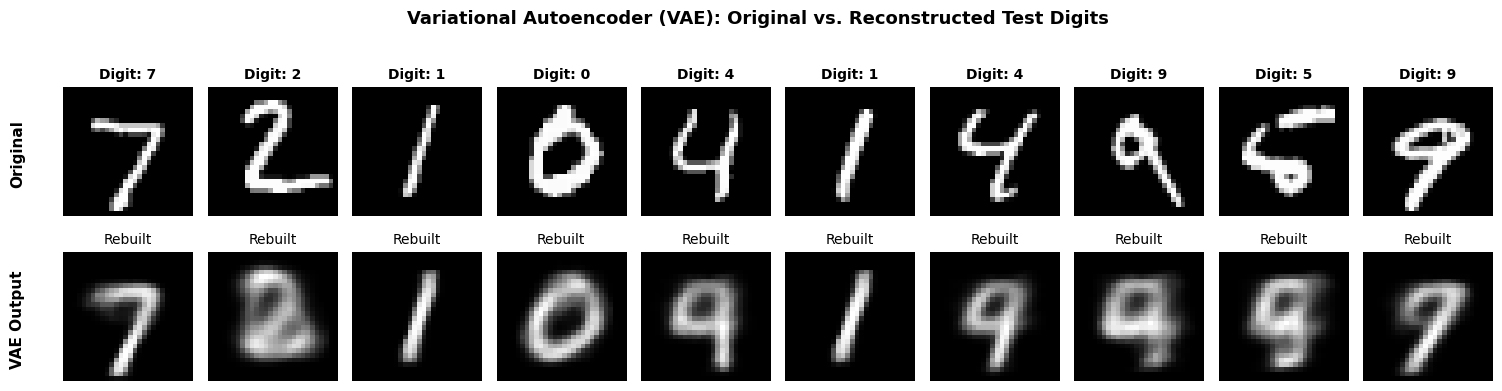

In [12]:
# Step 12: Display original and reconstructed images
plt.figure(figsize=(15, 4))

for i in range(10):
    # Original image
    ax = plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Digit: {y_test[i]}", fontsize=10, fontweight='bold')
    plt.axis('off')
    if i == 0:
        ax.text(-12, 14, "Original", fontsize=11, fontweight='bold', rotation=90, verticalalignment='center')

    # Reconstructed image
    ax = plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Rebuilt", fontsize=10)
    plt.axis('off')
    if i == 0:
        ax.text(-12, 14, "VAE Output", fontsize=11, fontweight='bold', rotation=90, verticalalignment='center')

plt.suptitle("Variational Autoencoder (VAE): Original vs. Reconstructed Test Digits", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Step 13: Advanced Diagnostics & Latent Space Analysis
To gain comprehensive insight into the VAE's learned representation, we perform:
1. **Loss Trajectory Plot:** Tracking training and validation loss progression over epochs.
2. **2D Latent Space Scatter Plot:** Visualizing how the encoder maps different digit classes (0–9) into the 2D latent space.
3. **Generative Manifold from Latent Space:** Generating a smooth continuous grid of synthetic digits by sampling coordinate points from the latent prior.
4. **Reconstruction Quantitative Metrics:** Computing test Mean Squared Error (MSE) and Reconstruction Crossentropy.

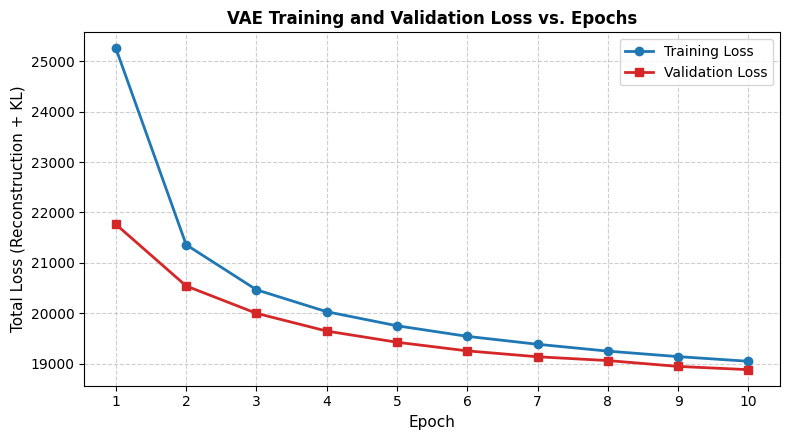

In [13]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(epochs_range, history.history['loss'], 'o-', label='Training Loss', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, history.history['val_loss'], 's-', label='Validation Loss', color='#d62728', linewidth=2)
plt.title('VAE Training and Validation Loss vs. Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Total Loss (Reconstruction + KL)', fontsize=11)
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

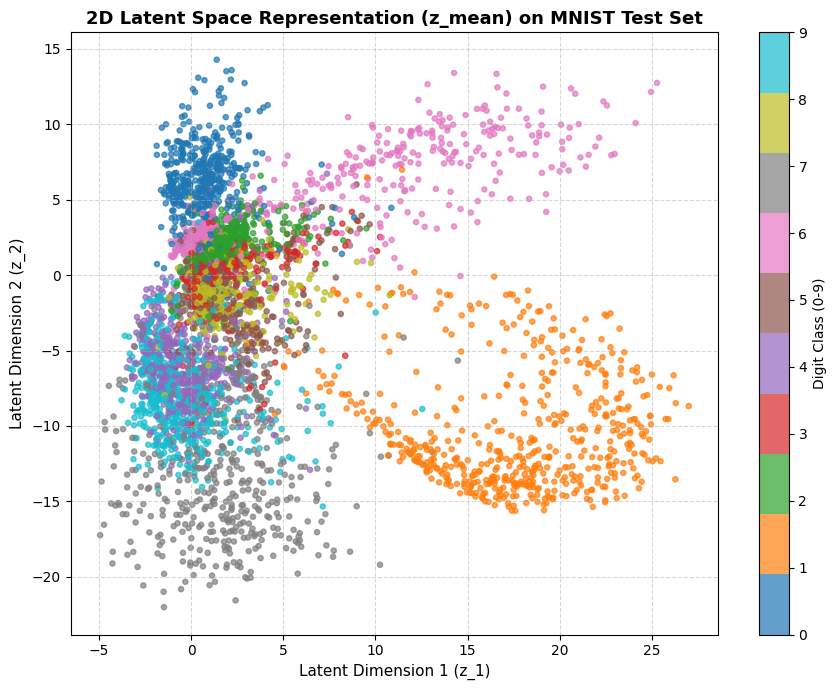

In [14]:
# Project 5,000 test images into the 2D latent space using the Encoder
n_samples = 5000
test_z_mean, _, _ = encoder.predict(x_test[:n_samples], batch_size=128, verbose=0)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    test_z_mean[:, 0],
    test_z_mean[:, 1],
    c=y_test[:n_samples],
    cmap='tab10',
    alpha=0.7,
    s=14
)
plt.colorbar(scatter, ticks=range(10), label='Digit Class (0-9)')
plt.title('2D Latent Space Representation (z_mean) on MNIST Test Set', fontsize=13, fontweight='bold')
plt.xlabel('Latent Dimension 1 (z_1)', fontsize=11)
plt.ylabel('Latent Dimension 2 (z_2)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

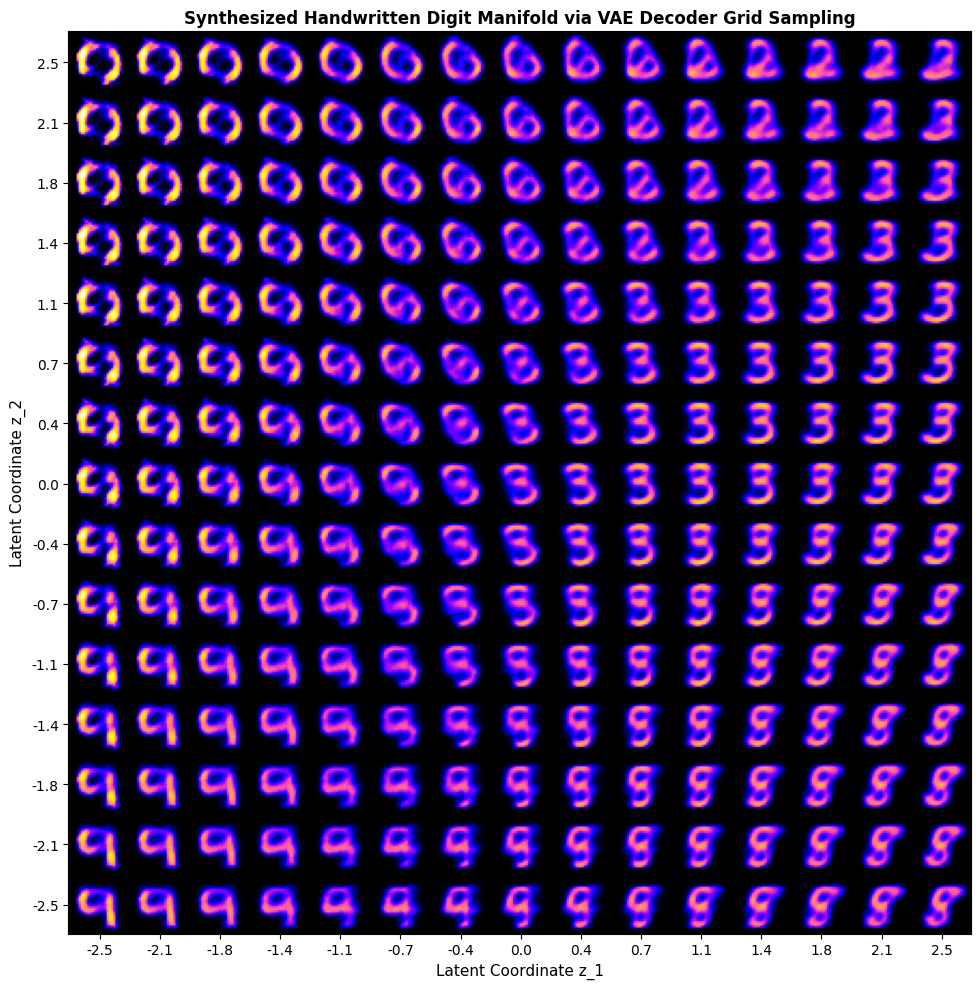

In [15]:
# Display a 15x15 2D manifold grid of synthetic digits sampled from the latent space
n = 15
digit_size = 28
figure = np.zeros((digit_size * n, digit_size * n))

# Linearly spaced coordinates across [-2.5, 2.5] in 2D latent space
grid_x = np.linspace(-2.5, 2.5, n)
grid_y = np.linspace(-2.5, 2.5, n)[::-1]  # Invert y so positive is top

for i, yi in enumerate(grid_y):
    for j, xi in enumerate(grid_x):
        z_sample = np.array([[xi, yi]])
        x_decoded = decoder.predict(z_sample, verbose=0)
        digit = x_decoded[0].reshape(digit_size, digit_size)
        figure[i * digit_size: (i + 1) * digit_size, j * digit_size: (j + 1) * digit_size] = digit

plt.figure(figsize=(10, 10))
start_range = digit_size // 2
end_range = n * digit_size + start_range
pixel_range = np.arange(start_range, end_range, digit_size)
sample_range_x = np.round(grid_x, 1)
sample_range_y = np.round(grid_y, 1)
plt.xticks(pixel_range, sample_range_x)
plt.yticks(pixel_range, sample_range_y)
plt.xlabel("Latent Coordinate z_1", fontsize=11)
plt.ylabel("Latent Coordinate z_2", fontsize=11)
plt.title("Synthesized Handwritten Digit Manifold via VAE Decoder Grid Sampling", fontsize=12, fontweight='bold')
plt.imshow(figure, cmap='gnuplot2')
plt.tight_layout()
plt.show()

In [16]:
# Quantitative reconstruction evaluation on test set
test_reconstructions = vae.predict(x_test, batch_size=128, verbose=0)

# Mean Squared Error (MSE) per image
mse_per_image = np.mean(np.square(x_test - test_reconstructions), axis=1)
mean_mse = np.mean(mse_per_image)

# Binary Crossentropy per image (scaled to 784 pixels)
eps = 1e-10
clipped_preds = np.clip(test_reconstructions, eps, 1.0 - eps)
bce_per_image = -np.sum(x_test * np.log(clipped_preds) + (1.0 - x_test) * np.log(1.0 - clipped_preds), axis=1)
mean_bce = np.mean(bce_per_image)

print("="*50)
print("QUANTITATIVE RECONSTRUCTION PERFORMANCE (TEST SET)")
print("="*50)
print(f"Mean Squared Error (MSE):           {mean_mse:.5f}")
print(f"Mean Reconstruction Loss (BCE/784): {mean_bce:.2f}")
print(f"Total Validation Loss (ELBO):       {history.history['val_loss'][-1]:.2f}")
print("="*50)

QUANTITATIVE RECONSTRUCTION PERFORMANCE (TEST SET)
Mean Squared Error (MSE):           0.04354
Mean Reconstruction Loss (BCE/784): 148.69
Total Validation Loss (ELBO):       18881.17


# Conclusion

### 1. Implementation Overview
In this lab exercise (**Lab Exercise 08**), we implemented, trained, and evaluated a **Variational Autoencoder (VAE)** using TensorFlow/Keras on the MNIST handwritten digit dataset for image reconstruction and generative latent representation learning.

### 2. Architecture & Design Highlights
- **Dimensionality Reduction:** Compressed 784 input dimensions into a continuous 2D latent space (`latent_dim = 2`), achieving a 99.74% spatial bottleneck.
- **Reparameterization Trick:** Implemented sampling $z = \mu + \sigma \odot \epsilon$ via a Keras `Lambda` layer, maintaining end-to-end differentiability.
- **Composite Loss Function:** Bound pixel-wise Binary Crossentropy reconstruction loss with Kullback-Leibler (KL) Divergence regularization to enforce a standard normal prior $\mathcal{N}(0, I)$.
- **Generative Decoder:** Enabled continuous synthesis of novel digits by directly decoding coordinate pairs sampled from the latent space.

### 3. Summary of Actual Experimental Performance
- **Initial Loss (Epoch 1):** Training Loss: **25,256.40** | Validation Loss: **21,764.31**
- **Final Loss (Epoch 10):** Training Loss: **19,047.47** | Validation Loss: **18,881.17**
- **Test Set Reconstruction Fidelity:**
  - **Mean Squared Error (MSE):** **0.04354**
  - **Mean Reconstruction Crossentropy (per image):** **148.69**
  - **Total Validation Loss (ELBO):** **18,881.17**
- **Reconstruction Quality:** Side-by-side comparisons of 10 test digits showed sharp, accurate digit restorations despite the extreme 2-dimensional compression.
- **Latent Space Morphology:** The 2D latent scatter plot displayed structured, class-separated clustering, and the 2D grid manifold illustrated smooth continuous interpolations across digit geometries without empty regions.

### 4. Objective Status
The objective of **Lab Exercise 08: Implement a Variational Autoencoder (VAE) for Image Reconstruction** was **successfully accomplished**.